<a href="https://colab.research.google.com/github/deepak9344/language-identification-lstm/blob/main/Language_Identification_LSTM_ipynb.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [15]:
import os, glob, zipfile, re, pickle
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping
from google.colab import files

# Upload your already-downloaded Kaggle dataset
uploaded = files.upload()

# Extract ZIP files automatically
for f in uploaded:
    if f.lower().endswith(".zip"):
        with zipfile.ZipFile(f, "r") as z:
            z.extractall("/content/language_data")

# Find CSV files
csv_files = [
    f for f in glob.glob("/content/**/*.csv", recursive=True)
    if "/sample_data/" not in f
]

if not csv_files:
    raise FileNotFoundError("Please upload the dataset ZIP or CSV file.")

# Load the largest CSV
df = pd.read_csv(max(csv_files, key=os.path.getsize))

print("Dataset loaded:", df.shape)
print("Columns:", df.columns.tolist())
display(df.head())

Saving dataset.csv to dataset.csv
Dataset loaded: (22000, 2)
Columns: ['Text', 'language']


,Text,language
0,klement gottwaldi surnukeha palsameeriti ning ...,Estonian
1,sebes joseph pereira thomas på eng the jesuit...,Swedish
2,ถนนเจริญกรุง อักษรโรมัน thanon charoen krung เ...,Thai
3,விசாகப்பட்டினம் தமிழ்ச்சங்கத்தை இந்துப் பத்திர...,Tamil
4,de spons behoort tot het geslacht haliclona en...,Dutch


In [16]:
# Identify text and language columns automatically
cols = {str(c).strip().lower(): c for c in df.columns}
text_col = next((cols[c] for c in ["text", "sentence", "content", "text_sample"] if c in cols), None)
label_col = next((cols[c] for c in ["language", "lang", "label", "target"] if c in cols), None)

if text_col is None or label_col is None:
    raise ValueError(f"Cannot identify text/language columns: {df.columns.tolist()}")

# Clean dataset
df = df[[text_col, label_col]].copy()
df.columns = ["text", "language"]
df = df.dropna()
df["text"] = df["text"].astype(str).str.strip().apply(lambda x: re.sub(r"\s+", " ", x))
df["language"] = df["language"].astype(str).str.strip()
df = df[(df["text"] != "") & (df["language"] != "")]
df = df.drop_duplicates(["text", "language"])

conflicts = df.groupby("text")["language"].nunique()
df = df[~df["text"].isin(conflicts[conflicts > 1].index)]
counts = df["language"].value_counts()
df = df[df["language"].isin(counts[counts >= 5].index)]

# Manageable subset
if len(df) > 20000:
    df, _ = train_test_split(df, train_size=20000, random_state=42, stratify=df["language"])

# Train, validation, and test split
X_train_text, X_temp_text, y_train_text, y_temp_text = train_test_split(
    df["text"].to_numpy(), df["language"].to_numpy(),
    test_size=0.2, random_state=42, stratify=df["language"]
)
X_val_text, X_test_text, y_val_text, y_test_text = train_test_split(
    X_temp_text, y_temp_text, test_size=0.5,
    random_state=42, stratify=y_temp_text
)

# Encode labels
encoder = LabelEncoder()
y_train = encoder.fit_transform(y_train_text)
y_val = encoder.transform(y_val_text)
y_test = encoder.transform(y_test_text)

# Character-level tokenization
tokenizer = Tokenizer(char_level=True, lower=False, filters="", oov_token="<OOV>", num_words=5000)
tokenizer.fit_on_texts(X_train_text)
vocab_size = min(5000, len(tokenizer.word_index) + 1)
max_len = 250

def prepare(texts):
    return pad_sequences(tokenizer.texts_to_sequences(texts), maxlen=max_len, padding="post", truncating="post")

X_train = prepare(X_train_text)
X_val = prepare(X_val_text)
X_test = prepare(X_test_text)
num_classes = len(encoder.classes_)

# Build and train LSTM
tf.keras.utils.set_random_seed(42)

model = Sequential([
    Embedding(vocab_size, 64, mask_zero=True),
    LSTM(64),
    Dropout(0.3),
    Dense(32, activation="relu"),
    Dropout(0.2),
    Dense(num_classes, activation="softmax")
])

model.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])

history = model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=8, batch_size=128,
    callbacks=[EarlyStopping(monitor="val_loss", patience=2, restore_best_weights=True)],
    verbose=1
)

print("Training completed!")

Epoch 1/8
125/125 ━━━━━━━━━━━━━━━━━━━━ 38s 290ms/step - accuracy: 0.2331 - loss: 2.4700 - val_accuracy: 0.4345 - val_loss: 1.7982
Epoch 2/8
125/125 ━━━━━━━━━━━━━━━━━━━━ 33s 268ms/step - accuracy: 0.4923 - loss: 1.5269 - val_accuracy: 0.5720 - val_loss: 1.2748
Epoch 3/8
125/125 ━━━━━━━━━━━━━━━━━━━━ 40s 262ms/step - accuracy: 0.5663 - loss: 1.2566 - val_accuracy: 0.6740 - val_loss: 1.0261
Epoch 4/8
125/125 ━━━━━━━━━━━━━━━━━━━━ 34s 269ms/step - accuracy: 0.6248 - loss: 1.0680 - val_accuracy: 0.6010 - val_loss: 1.2794
Epoch 5/8
125/125 ━━━━━━━━━━━━━━━━━━━━ 34s 269ms/step - accuracy: 0.6047 - loss: 1.1311 - val_accuracy: 0.7185 - val_loss: 0.8526
Epoch 6/8
125/125 ━━━━━━━━━━━━━━━━━━━━ 40s 265ms/step - accuracy: 0.6564 - loss: 1.0204 - val_accuracy: 0.6620 - val_loss: 0.9729
Epoch 7/8
125/125 ━━━━━━━━━━━━━━━━━━━━ 36s 287ms/step - accuracy: 0.6659 - loss: 0.9381 - val_accuracy: 0.7735 - val_loss: 0.7433
Epoch 8/8
125/125 ━━━━━━━━━━━━━━━━━━━━ 33s 267ms/step - accuracy: 0.7052 - loss: 0.8576 - 

Accuracy:  0.7935
Precision: 0.799
Recall:    0.7931
F1-score:  0.7859

Classification Report:

              precision    recall  f1-score   support

      Arabic       0.92      0.99      0.95        91
     Chinese       0.97      0.99      0.98        91
       Dutch       0.26      0.26      0.26        91
     English       0.30      0.18      0.23        92
    Estonian       0.81      0.87      0.84        92
      French       0.51      0.74      0.60        91
       Hindi       1.00      0.99      0.99        90
  Indonesian       0.64      0.78      0.70        89
    Japanese       0.98      0.96      0.97        92
      Korean       1.00      1.00      1.00        92
       Latin       0.91      0.55      0.69        87
     Persian       0.86      0.96      0.91        91
   Portugese       0.50      0.27      0.35        91
      Pushto       1.00      0.53      0.69        91
    Romanian       0.93      0.97      0.95        92
     Russian       0.99      0.98      

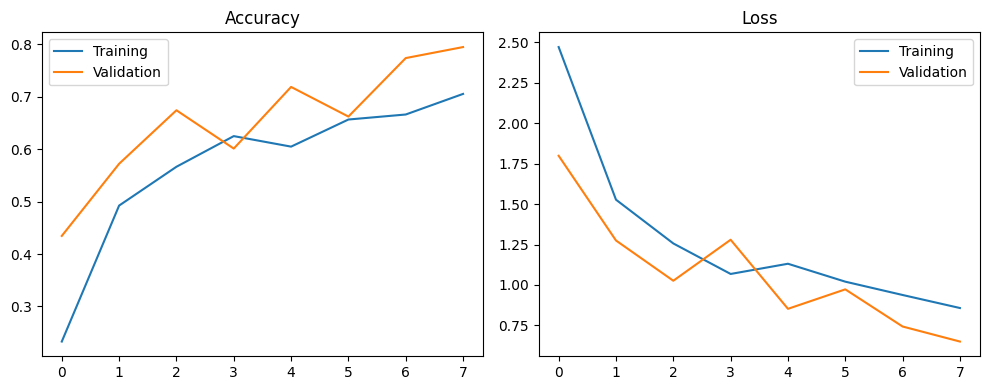

Text: Hello, how are you?
Predicted language: Portugese
Confidence: 26.25%
Text: Bonjour, comment allez-vous?
Predicted language: Portugese
Confidence: 18.88%
Text: வணக்கம்
Predicted language: Tamil
Confidence: 99.97%


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [17]:
# Evaluate model
predictions = np.argmax(model.predict(X_test, verbose=0), axis=1)

print("Accuracy: ", round(accuracy_score(y_test, predictions), 4))
print("Precision:", round(precision_score(y_test, predictions, average="macro", zero_division=0), 4))
print("Recall:   ", round(recall_score(y_test, predictions, average="macro", zero_division=0), 4))
print("F1-score: ", round(f1_score(y_test, predictions, average="macro", zero_division=0), 4))

print("\nClassification Report:\n")
print(classification_report(y_test, predictions, target_names=encoder.classes_, zero_division=0))

# Training graphs
plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Training")
plt.plot(history.history["val_accuracy"], label="Validation")
plt.title("Accuracy")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Training")
plt.plot(history.history["val_loss"], label="Validation")
plt.title("Loss")
plt.legend()
plt.tight_layout()
plt.show()

# Predict new text
def predict_language(text):
    seq = prepare([text])
    prob = model.predict(seq, verbose=0)[0]
    i = np.argmax(prob)
    print("Text:", text)
    print("Predicted language:", encoder.classes_[i])
    print("Confidence:", f"{prob[i]:.2%}")

predict_language("Hello, how are you?")
predict_language("Bonjour, comment allez-vous?")
predict_language("வணக்கம்")

# Save and download model files
model.save("/content/language_identification_lstm.keras")

with open("/content/tokenizer.pkl", "wb") as f:
    pickle.dump(tokenizer, f)

with open("/content/label_encoder.pkl", "wb") as f:
    pickle.dump(encoder, f)

with zipfile.ZipFile("/content/language_identification_model.zip", "w") as z:
    for f in ["language_identification_lstm.keras", "tokenizer.pkl", "label_encoder.pkl"]:
        z.write("/content/" + f, f)

files.download("/content/language_identification_model.zip")